# Anotação funcional de *Colletotrichum abscissum* Ca142 com o eggNOG-mapper

**Montagem:** GCA_023376855.1 ·

**Linhagem:** Ca142 ·

**Entrada:** as 15.499 proteínas de `protein.faa`

A análise exploratória (cadernos 01 a 06) avaliou a **qualidade** dos genes. Este caderno começa a responder **o que
eles fazem**, com a ferramenta mais útil para a escolha de alvos de RNAi que dá para rodar num computador pessoal.

**Por que o eggNOG-mapper**

- **Funciona por ortologia.** Para cada proteína da Ca142, encontra o ortólogo mais próximo no banco eggNOG e herda
  as anotações do grupo de ortólogos. Isso liga cada gene a genes de fungos-modelo, onde já se sabe quais são
  essenciais.
- **Entrega quase tudo de que o projeto precisa numa só execução:** nome padronizado do gene, descrição, categoria
  funcional (COG), termos GO, número EC, KEGG (ortólogo e vias), família CAZy e domínios Pfam.
- **Roda localmente.** Usa o DIAMOND, que é rápido, e não exige contêineres. A alternativa mais completa para
  domínios, o InterProScan, fica para o cluster.

**Requisitos**

| Recurso | Necessário |
|---|---|
| Disco | cerca de **50 GB** para os bancos (~40 GB de anotações e ~9 GB do banco do DIAMOND), mais folga para o download |
| Memória | 16 GB ou mais é confortável |
| Tempo | o download leva horas; a execução completa, de dezenas de minutos a algumas horas |

**Roteiro**

1. Preparação (no terminal, uma única vez)
2. Configuração
3. Teste com um subconjunto de proteínas
4. Execução completa
5. Leitura dos resultados
6. Cobertura da anotação
7. Proteínas hipotéticas que ganharam função
8. Categorias funcionais (COG)
9. Vias metabólicas (KEGG)
10. Alvos clássicos de fungicidas e maquinaria de RNAi
11. Integração com a análise exploratória
12. Tabelas salvas
13. Síntese e próximos passos

**Pré-requisito:** ter executado os cadernos 03 a 06. O caderno usa `data/processed/ca142_genes_final.tsv`.

## 1. Preparação (no terminal, uma única vez)

### 1.1 Ambiente conda próprio, com Python 3.11

O eggNOG-mapper fica num ambiente separado, chamado `emapper`, como o BUSCO:

```bash
conda create -n emapper -c conda-forge -c bioconda "python=3.11" eggnog-mapper
conda run -n emapper emapper.py --version
```

**Atenção ao `"python=3.11"`.** A versão atual do eggNOG-mapper (2.1.15) usa o módulo `distutils`, que deixou de
existir no Python 3.12. Sem fixar a versão, o conda instala o Python mais novo e o programa falha logo ao abrir, com
`ModuleNotFoundError: No module named 'distutils'`.

O comando `--version` deve mostrar `emapper-2.1.15` e `Expected eggNOG DB version: 5.0.2`.

### 1.2 Bancos de dados

Os bancos ocupam cerca de 50 GB. Escolha uma pasta num disco com pelo menos **60 GB livres** (o download guarda os
arquivos compactados e os descompactados ao mesmo tempo).

**Antes do download, corrija o endereço do servidor.** O script `download_eggnog_data.py` da versão 2.1.15 ainda
aponta para `eggnogdb.embl.de`, que foi desativado; os bancos estão agora em `eggnog5.embl.de`. Sem a correção, o
download falha com `unable to resolve host address 'eggnogdb.embl.de'`:

```bash
wget --spider http://eggnog5.embl.de/download/emapperdb-5.0.2/eggnog.db.gz   # deve responder 200 OK
ARQ=$(conda info --base)/envs/emapper/bin/download_eggnog_data.py
sed -i.bak 's/eggnogdb\.embl\.de/eggnog5.embl.de/g' "$ARQ"
grep -n "embl.de" "$ARQ"                                                      # deve mostrar eggnog5
```

Se o ambiente for reinstalado, repita a correção. Depois, na raiz do projeto:

```bash
mkdir eggnog_db
nohup conda run --no-capture-output -n emapper download_eggnog_data.py -y --data_dir eggnog_db > eggnog_download.log 2>&1 &
tail -f eggnog_download.log
```

- `-y` responde "sim" às perguntas do script. Ele baixa o banco de anotações (`eggnog.db`), o de taxonomia
  (`eggnog.taxa.db`) e o banco de proteínas do DIAMOND (`eggnog_proteins.dmnd`).
- O `nohup … &` deixa o download rodando em segundo plano, com o registro em `eggnog_download.log`; o `Ctrl+C` só fecha
  o `tail`.
- Rode o download no terminal, e não numa célula do caderno: leva horas, e uma interrupção do kernel o perderia.
- Se o projeto for um repositório git, inclua `eggnog_db/` no `.gitignore`.

Na seção 2, informe a pasta escolhida em `DIR_DB`.

## 2. Configuração

A célula define os caminhos, localiza o eggNOG-mapper (pelo `conda run`, como no caderno do BUSCO) e confere se os
três arquivos principais do banco estão na pasta indicada.

Duas escolhas ficam em variáveis no topo da célula:

- **`DIR_DB`:** a pasta dos bancos (seção 1.2).
- **`TAX_SCOPE`:** de que grupos de organismos as anotações podem ser herdadas. Usamos `"auto"`, o padrão do programa:
  ele escolhe, para cada proteína, o grupo de ortólogos mais restrito dentro de uma lista de grandes grupos. No teste
  (seção 3), todas as anotações da Ca142 vieram do nível **Fungi** (`max_annot_lvl = 4751|Fungi`).

**Por que não restringir a Sordariomycetes**, a classe de *Colletotrichum*? Porque grande parte do conhecimento sobre
genes de fungos vem da levedura *Saccharomyces cerevisiae*, que não é Sordariomycetes. Os nomes que o teste devolveu
(`SDH1` a `SDH4`, `emi5`) são nomes de levedura. Restringir a Sordariomycetes daria grupos de ortólogos mais precisos,
mas com menos anotação.

In [1]:
import os
import re
import shutil
import subprocess
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from Bio import SeqIO


RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

# ------------------------------------------------------------------ escolhas
DIR_DB = RAIZ / "eggnog_db"  # pasta dos bancos (seção 1.2)
ENV_EMAPPER = "emapper"        # ambiente conda do eggNOG-mapper
TAX_SCOPE = "auto"             # 4751 = Fungi; use "auto" para não restringir
# ------------------------------------------------------------------

ACCESSION = "GCA_023376855.1"

DIR_DADOS = RAIZ / "data" / "raw" / "ca142" / "ncbi_dataset" / "data" / ACCESSION
DIR_PROC = RAIZ / "data" / "processed"
DIR_FIG = RAIZ / "results" / "figures"
DIR_EMAPPER = RAIZ / "results" / "eggnog"
for d in (DIR_FIG, DIR_EMAPPER):
    d.mkdir(parents=True, exist_ok=True)

ARQ_PROT = DIR_DADOS / "protein.faa"
ARQ_FINAL = DIR_PROC / "ca142_genes_final.tsv"
assert ARQ_FINAL.exists(), "Rode antes os cadernos 03 a 06 (o 06 gera ca142_genes_final.tsv)."

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 60)

AZUL, LARANJA = "#2a78d6", "#eb6834"
TINTA, TINTA_2, GRADE, FUNDO = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({
    "figure.figsize": (7.5, 4.2), "figure.dpi": 110, "savefig.dpi": 200,
    "figure.facecolor": FUNDO, "axes.facecolor": FUNDO, "savefig.facecolor": FUNDO,
    "axes.edgecolor": TINTA_2, "axes.labelcolor": TINTA_2, "axes.titlecolor": TINTA,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 10, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRADE, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": TINTA_2, "ytick.color": TINTA_2, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "legend.frameon": False, "legend.fontsize": 9, "font.size": 10,
})

def fmt(n):
    return f"{n:,.0f}".replace(",", ".")

def barras_horizontais(rotulos, valores, titulo, xlabel, nome_fig, textos=None, altura=None):
    """Gráfico de barras horizontais, do maior (em cima) para o menor."""
    n = len(valores)
    fig, ax = plt.subplots(figsize=(7.5, altura or max(2.4, 0.32 * n + 1)))
    y = np.arange(n)[::-1]
    ax.barh(y, valores, color=AZUL, height=0.62)
    for yi, v, t in zip(y, valores, textos or [None] * n):
        ax.annotate(t if t is not None else fmt(v), (v, yi), xytext=(4, 0), textcoords="offset points",
                    va="center", color=TINTA, fontsize=8.5)
    ax.set_yticks(y, rotulos)
    ax.set_xlim(0, max(valores) * 1.22 if n else 1)
    ax.set_xlabel(xlabel)
    ax.set_title(titulo)
    ax.grid(axis="y", visible=False)
    fig.savefig(DIR_FIG / f"{nome_fig}.png", bbox_inches="tight")
    plt.show()

def localizar_emapper():
    """Comando para chamar o emapper.py do ambiente conda, e a versão encontrada."""
    conda = os.environ.get("CONDA_EXE") or shutil.which("conda")
    if not conda:
        for pasta in ("anaconda3", "miniconda3", "miniforge3"):
            caminho = Path.home() / pasta / "bin" / "conda"
            if caminho.exists():
                conda = str(caminho)
                break
    if not conda:
        return None, None
    prefixo = [conda, "run", "--no-capture-output", "-n", ENV_EMAPPER]
    try:
        r = subprocess.run(prefixo + ["emapper.py", "--version"], capture_output=True, text=True, timeout=180)
    except (OSError, subprocess.TimeoutExpired):
        return None, None
    m = re.search(r"emapper-(\d+\.\d+\.\d+)", r.stdout + r.stderr)
    if r.returncode != 0 or not m:
        print((r.stdout + r.stderr)[-800:])
        return None, None
    return prefixo, m.group(1)

PREFIXO, VERSAO = localizar_emapper()
if PREFIXO is None:
    raise RuntimeError('eggNOG-mapper não encontrado. No terminal: '
                       'conda create -n emapper -c conda-forge -c bioconda "python=3.11" eggnog-mapper')
print("eggNOG-mapper", VERSAO)

BANCOS = ["eggnog.db", "eggnog.taxa.db", "eggnog_proteins.dmnd"]
faltando = [b for b in BANCOS if not (DIR_DB / b).exists()]
if faltando:
    DIR_DB.mkdir(parents=True, exist_ok=True)
    livre = shutil.disk_usage(DIR_DB).free / 1e9
    raise RuntimeError(
        f"Bancos ausentes em {DIR_DB}: {', '.join(faltando)}.\n"
        f"Espaço livre nesse disco: {livre:.0f} GB (são necessários cerca de 60 GB para o download).\n"
        f"No terminal: conda run --no-capture-output -n {ENV_EMAPPER} download_eggnog_data.py -y --data_dir {DIR_DB}")
tamanhos = {b: (DIR_DB / b).stat().st_size / 1e9 for b in BANCOS}
print("Bancos em", DIR_DB)
for b, t in tamanhos.items():
    print(f"  {b:22s} {t:6.1f} GB")

eggNOG-mapper 2.1.15
Bancos em /home/denilson/rep/dfb/cabs/eggnog_db
  eggnog.db                41.4 GB
  eggnog.taxa.db            0.3 GB
  eggnog_proteins.dmnd      9.3 GB


**Como ler:** a saída deve mostrar a versão do programa e os três bancos com seus tamanhos. Somados, eles passam de
40 GB; um arquivo com poucos MB indica download interrompido (apague-o e baixe de novo).

## 3. Teste com um subconjunto de proteínas

Antes de anotar as 15.499 proteínas, rodamos o eggNOG-mapper num conjunto pequeno, para conferir se tudo funciona e
ver o formato da saída. O conjunto tem:

- as **6 proteínas da SDH** encontradas no caderno 06 (as quatro subunidades e os dois fatores de montagem);
- as **13 proteínas da maquinaria de RNAi** (Dicer, Argonautas, RdRP e afins);
- **200 proteínas sorteadas** (com semente fixa, para o sorteio ser sempre o mesmo).

As do SDH e do RNAi servem de controle: já sabemos o que são, então dá para julgar se a anotação está certa.

A função `rodar_emapper` monta e executa o comando. As opções usadas:

| Opção | Significado |
|---|---|
| `-i`, `--itype proteins` | arquivo de entrada, com proteínas |
| `-m diamond` | busca dos ortólogos com o DIAMOND |
| `-o`, `--output_dir` | prefixo e pasta dos resultados |
| `--data_dir` | pasta dos bancos |
| `--tax_scope` | grupo de onde as anotações podem ser herdadas (seção 2) |
| `--cpu` | número de núcleos do processador |
| `--override` | sobrescreve resultados anteriores com o mesmo nome |

Mesmo com poucas proteínas, o teste leva uns 10 minutos: o DIAMOND precisa ler o banco de proteínas inteiro. Se o
resultado do teste já existir, a célula não roda o eggNOG-mapper de novo; para refazer, apague
`results/eggnog/teste.emapper.annotations`.

In [4]:
final = pd.read_csv(ARQ_FINAL, sep="\t")
for coluna in ("busco_descricao", "dist_bloco_rip"):
    if coluna not in final.columns:
        print(f"Aviso: a coluna '{coluna}' não está em ca142_genes_final.tsv. Rode de novo o caderno 06 (versão revisada).")
        final[coluna] = pd.NA
final["busco_descricao"] = final["busco_descricao"].astype("string")

controles_sdh = final[final["busco_descricao"].str.contains("succinate dehydrogenase", case=False, na=False)]
PADRAO_RNAI = "dicer|argonaute|piwi|RNA-dependent RNA polymerase|RNA-directed RNA polymerase|RNase3"
controles_rnai = final[final["produto"].fillna("").str.contains(PADRAO_RNAI, case=False, regex=True)
                       | final["busco_descricao"].str.contains(PADRAO_RNAI, case=False, regex=True, na=False)]
controles = pd.concat([controles_sdh.assign(grupo="SDH"), controles_rnai.assign(grupo="RNAi")])
sorteadas = final[~final["protein_id"].isin(controles["protein_id"])].sample(200, random_state=42)
teste_ids = set(controles["protein_id"]) | set(sorteadas["protein_id"])

ARQ_TESTE = DIR_EMAPPER / "teste_proteinas.faa"
n = SeqIO.write((r for r in SeqIO.parse(ARQ_PROT, "fasta") if r.id in teste_ids), ARQ_TESTE, "fasta")
print(f"Conjunto de teste: {n} proteínas ({len(controles_sdh)} da SDH, {len(controles_rnai)} do RNAi, 200 sorteadas)")

def rodar_emapper(arq_fasta, prefixo, nucleos=None):
    """Executa o eggNOG-mapper e devolve o caminho do arquivo de anotações."""
    nucleos = nucleos or max(1, (os.cpu_count() or 2) - 1)
    temp = DIR_EMAPPER / "tmp"
    temp.mkdir(exist_ok=True)
    cmd = PREFIXO + ["emapper.py", "-i", str(arq_fasta), "--itype", "proteins", "-m", "diamond",
                     "-o", prefixo, "--output_dir", str(DIR_EMAPPER), "--data_dir", str(DIR_DB),
                     "--tax_scope", TAX_SCOPE, "--cpu", str(nucleos), "--temp_dir", str(temp), "--override"]
    print("Executando:", " ".join(cmd), "\n")
    with subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True) as proc:
        for linha in proc.stdout:
            if any(p in linha for p in ("Error", "ERROR", "Done", "Total", "queries", "Searching", "Annotating")):
                print(linha.rstrip())
    arq = DIR_EMAPPER / f"{prefixo}.emapper.annotations"
    if proc.returncode != 0 or not arq.exists():
        raise RuntimeError("O eggNOG-mapper terminou com erro. Veja as mensagens acima.")
    return arq

ARQ_ANOT_TESTE = DIR_EMAPPER / "teste.emapper.annotations"
if ARQ_ANOT_TESTE.exists():
    print("Resultado do teste já existe; eggNOG-mapper não foi executado de novo (apague o arquivo para refazer).")
else:
    ARQ_ANOT_TESTE = rodar_emapper(ARQ_TESTE, "teste")

Conjunto de teste: 219 proteínas (6 da SDH, 13 do RNAi, 200 sorteadas)
Executando: /home/denilson/anaconda3/bin/conda run --no-capture-output -n emapper emapper.py -i /home/denilson/rep/dfb/cabs/results/eggnog/teste_proteinas.faa --itype proteins -m diamond -o teste --output_dir /home/denilson/rep/dfb/cabs/results/eggnog --data_dir /home/denilson/rep/dfb/cabs/eggnog_db --tax_scope auto --cpu 7 --temp_dir /home/denilson/rep/dfb/cabs/results/eggnog/tmp --override 

Done
Total hits processed: 190
Total time: 635 secs


### 3.1 Formato da saída

O eggNOG-mapper grava três arquivos com o prefixo escolhido:

- `.emapper.hits`: os alinhamentos do DIAMOND;
- `.emapper.seed_orthologs`: o melhor ortólogo ("semente") de cada proteína;
- `.emapper.annotations`: **o resultado principal**, uma linha por proteína anotada.

O arquivo de anotações começa com linhas de comentário (`##`), que registram a data, a versão e o comando. Depois vem
o cabeçalho (`#query…`) e uma linha por proteína. Campos sem informação aparecem como `-`. As colunas:

| Coluna | Conteúdo |
|---|---|
| `query` | o `protein_id` da Ca142 |
| `seed_ortholog`, `evalue`, `score` | o ortólogo mais próximo no banco e a qualidade do alinhamento |
| `eggNOG_OGs` | os grupos de ortólogos, em vários níveis taxonômicos |
| `max_annot_lvl` | o nível taxonômico de onde a anotação foi herdada |
| `COG_category` | categoria funcional (uma ou mais letras; seção 8) |
| `Description`, `Preferred_name` | descrição e nome curto do gene |
| `GOs`, `EC` | termos Gene Ontology e número de enzima |
| `KEGG_ko`, `KEGG_Pathway`, `KEGG_Module`… | ortólogo KEGG (KO) e vias |
| `CAZy` | família de enzima ativa em carboidratos |
| `PFAMs` | domínios Pfam |

A função `ler_emapper` lê esse arquivo para uma tabela, ignorando os comentários e trocando `-` por vazio.

In [5]:
def ler_emapper(arquivo):
    cabecalho, linhas = None, []
    with open(arquivo) as f:
        for linha in f:
            if linha.startswith("##"):
                continue
            if linha.startswith("#"):
                cabecalho = linha[1:].rstrip("\n").split("\t")
                continue
            if linha.strip():
                linhas.append(linha.rstrip("\n").split("\t"))
    tabela = pd.DataFrame(linhas, columns=cabecalho)
    return tabela.replace("-", pd.NA).rename(columns={"query": "protein_id"})

teste = ler_emapper(ARQ_ANOT_TESTE)
print(f"Proteínas anotadas no teste: {len(teste)} de {n}")

COLS_VER = ["protein_id", "Preferred_name", "Description", "COG_category", "KEGG_ko", "max_annot_lvl"]
ver_controles = controles[["grupo", "locus_tag", "protein_id", "produto"]].merge(teste[COLS_VER], on="protein_id", how="left")
ver_controles.drop(columns="protein_id")

Proteínas anotadas no teste: 190 de 219


,grupo,locus_tag,produto,Preferred_name,Description,COG_category,KEGG_ko,max_annot_lvl
0,SDH,CABS02_06926,succinate dehydrogenase cytochrome b subunit,SDH3,Succinate dehydrogenase cytochrome,G,ko:K00236,4751|Fungi
1,SDH,CABS02_11911,CybS protein,SDH4,succinate dehydrogenase,CU,"ko:K00237,ko:K17791",4751|Fungi
2,SDH,CABS02_13316,hypothetical protein,emi5,Plays an essential role in the assembly of succinate deh...,S,"ko:K18168,ko:K20352",4751|Fungi
3,SDH,CABS02_13458,hypothetical protein,NaN,Protein of unknown function (DUF1674),S,NaN,4751|Fungi
4,SDH,CABS02_14282,succinate dehydrogenase iron-sulfur subunit,SDH2,Iron-sulfur protein (IP) subunit of succinate dehydrogen...,C,ko:K00235,4751|Fungi
5,SDH,CABS02_14283,succinate dehydrogenase,SDH1,Flavoprotein (FP) subunit of succinate dehydrogenase (SD...,C,ko:K00234,4751|Fungi
6,RNAi,CABS02_02578,argonaute siRNA chaperone complex subunit Arb1,NaN,Argonaute siRNA chaperone (ARC) complex subunit Arb1,S,NaN,4751|Fungi
7,RNAi,CABS02_04245,RNase3 domain-containing protein,NaN,RNase3 domain-containing protein,A,ko:K03685,4751|Fungi
8,RNAi,CABS02_04413,RNase3 domain-containing protein,DCL2,Belongs to the helicase family. Dicer subfamily,A,NaN,4751|Fungi
9,RNAi,CABS02_04673,RNA-dependent RNA polymerase,NaN,RNA polymerase,A,ko:K11699,4751|Fungi


**Como ler:** a tabela mostra, para cada proteína de controle, o nome que ela tinha na anotação original (`produto`)
e o que o eggNOG-mapper atribuiu.

**Resultado do teste (219 proteínas, 11 min):** 190 proteínas (87%) receberam anotação, e os controles foram
identificados corretamente.

*SDH: as quatro subunidades com o KO certo*

| Gene | Anotação original | eggNOG-mapper | Proteína |
|---|---|---|---|
| CABS02_14283 | succinate dehydrogenase | SDH1, K00234 | SdhA (flavoproteína) |
| CABS02_14282 | iron-sulfur subunit | SDH2, K00235 | SdhB (ferro-enxofre) |
| CABS02_06926 | cytochrome b subunit | SDH3, K00236 | SdhC |
| CABS02_11911 | CybS protein | SDH4, K00237 | SdhD |
| CABS02_13316 | hypothetical protein | emi5 | fator de montagem Sdh5 (SDHAF2) |
| CABS02_13458 | hypothetical protein | DUF1674 | fator de montagem Sdh8 (SDHAF4) |

- **Uma proteína hipotética ganhou função:** CABS02_13316 é o Emi5, nome alternativo do Sdh5 em levedura.
- **CABS02_13458 continua "sem função" para o eggNOG-mapper.** O domínio DUF1674 é a família do Sdh8/SDHAF4, mas o nome
  do domínio diz "Protein of unknown function". No nome de consenso (seção 7), ela recebe a descrição do BUSCO.
- **A SdhD tem um segundo KO (K17791).** Em levedura, o Sdh4 tem uma proteína parecida, o Tim18, que atua na importação
  de proteínas para a mitocôndria. A categoria COG "CU" (energia + tráfego intracelular) combina com isso. O grupo de
  ortólogos no nível de Fungi junta as duas; a descrição e o nome indicam SdhD.
- **A categoria COG de um gene isolado não é confiável:** a SdhC recebeu "G" (carboidratos). A COG serve para o
  retrato geral do proteoma (seção 8).

*RNAi: o núcleo da maquinaria confirmado (2 Dicer, 4 Argonautas, 4 RdRP)*

Das 13 proteínas do controle, três não são do núcleo da maquinaria:

- **CABS02_04245** é uma RNase III do tipo Rnt1 (KO K03685), que processa RNA ribossômico, e não uma Dicer. Entrou no
  controle porque tem "RNase3" no nome.
- **CABS02_02578** é a Arb1, uma chaperona das Argonautas: acessória, não uma enzima central.
- **CABS02_07952** é hipotética e tem ortólogo em fungos, mas nenhuma anotação.

**Lição para a seção 10:** nem todo gene recebeu o KO esperado. Pelo KO, seriam só 1 Dicer (falta a DCL2,
CABS02_04413) e 2 RdRP (faltam CABS02_10257 e 14424). Por isso a seção 10 identifica cada proteína por três
critérios: KO, nome curto ou descrição.

## 4. Execução completa

Agora as 15.499 proteínas. A célula só executa se `EXECUTAR_COMPLETO` for `True` e se ainda não houver resultado;
para refazer, apague `results/eggnog/ca142.emapper.annotations`.

O teste levou cerca de 10 minutos para 219 proteínas, a maior parte só para carregar o banco. A execução completa deve
levar algumas horas. Enquanto roda, o computador fica lento.

**Alternativa mais segura: rodar no terminal.** Se o notebook perder a conexão com o kernel, ou se o computador entrar
em suspensão, a execução dentro do caderno se perde. No terminal, na raiz do projeto, com `nohup`, ela continua mesmo
se o VS Code for fechado:

```bash
nohup conda run --no-capture-output -n emapper emapper.py \
  -i data/raw/ca142/ncbi_dataset/data/GCA_023376855.1/protein.faa --itype proteins -m diamond \
  -o ca142 --output_dir results/eggnog --data_dir eggnog_db --tax_scope auto \
  --cpu 7 --temp_dir results/eggnog/tmp --override > results/eggnog/ca142.log 2>&1 &
tail -f results/eggnog/ca142.log
```

Desative a suspensão automática do computador enquanto roda. Quando terminar (o registro mostra `Done`), rode o
caderno normalmente: a célula abaixo encontra o resultado e não executa o eggNOG-mapper de novo.

In [ ]:
EXECUTAR_COMPLETO = False  # True para rodar o eggNOG-mapper completo (demorado); False para usar o resultado do teste

ARQ_ANOT = DIR_EMAPPER / "ca142.emapper.annotations"
if ARQ_ANOT.exists():
    print("Resultado completo já existe; eggNOG-mapper não foi executado de novo.")
elif EXECUTAR_COMPLETO:
    ARQ_ANOT = rodar_emapper(ARQ_PROT, "ca142")
else:
    print("Execução completa desligada (EXECUTAR_COMPLETO = False). As seções seguintes usam o resultado do teste.")
    ARQ_ANOT = ARQ_ANOT_TESTE

Resultado completo já existe; eggNOG-mapper não foi executado de novo.


## 5. Leitura dos resultados

Lemos o arquivo de anotações e o juntamos à tabela final de genes do caderno 06, pelo `protein_id`. As colunas do
eggNOG-mapper recebem o prefixo `eggnog_` para não se confundirem com as que já existiam.

Também extraímos:

- `ko`: os números KO sem o prefixo `ko:` (por exemplo, `K00234`);
- `vias`: só os mapas de referência do KEGG (`map00020` etc.). O arquivo traz cada via duas vezes, como `ko00020` e
  `map00020`.

In [28]:
emap = ler_emapper(ARQ_ANOT)
emap["ko"] = emap["KEGG_ko"].str.replace("ko:", "", regex=False)
emap["vias"] = emap["KEGG_Pathway"].map(
    lambda v: ",".join(sorted(p for p in v.split(",") if p.startswith("map"))) if isinstance(v, str) else pd.NA)
emap = emap.replace("", pd.NA)

renomear = {c: f"eggnog_{c}" for c in emap.columns if c != "protein_id"}
anot = final.merge(emap.rename(columns=renomear), on="protein_id", how="left")
anot["tem_ortologo"] = anot["eggnog_seed_ortholog"].notna()

completo = ARQ_ANOT != ARQ_ANOT_TESTE
print(f"Linhas no arquivo de anotações: {fmt(len(emap))}"
      + ("" if completo else "  (resultado do TESTE: as porcentagens abaixo valem só para o subconjunto)"))
UNIVERSO = anot if completo else anot[anot["protein_id"].isin(teste_ids)]
print(f"Proteínas consideradas nas análises: {fmt(len(UNIVERSO))}")

Linhas no arquivo de anotações: 13.783
Proteínas consideradas nas análises: 15.499


## 6. Cobertura da anotação

Para cada tipo de informação, contamos quantas proteínas a receberam. Uma proteína pode ter um ortólogo no banco e,
ainda assim, ficar sem algum campo (por exemplo, sem KO, se o grupo de ortólogos não tem correspondência no KEGG).

,proteínas,%
Ortólogo no eggNOG,13783,88.9
Descrição,11040,71.2
Nome curto (Preferred_name),2808,18.1
Categoria COG,11040,71.2
Termos GO,3992,25.8
Domínios Pfam,10811,69.8
Ortólogo KEGG (KO),4837,31.2
Via KEGG,3059,19.7
Número EC,2416,15.6
Família CAZy,247,1.6


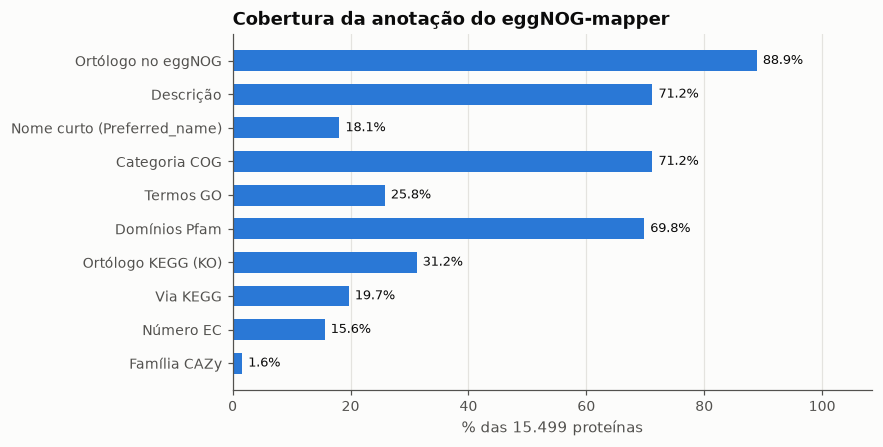

In [29]:
CAMPOS = {
    "Ortólogo no eggNOG": "eggnog_seed_ortholog",
    "Descrição": "eggnog_Description",
    "Nome curto (Preferred_name)": "eggnog_Preferred_name",
    "Categoria COG": "eggnog_COG_category",
    "Termos GO": "eggnog_GOs",
    "Domínios Pfam": "eggnog_PFAMs",
    "Ortólogo KEGG (KO)": "eggnog_ko",
    "Via KEGG": "eggnog_vias",
    "Número EC": "eggnog_EC",
    "Família CAZy": "eggnog_CAZy",
}
cobertura = pd.DataFrame({"proteínas": {r: int(UNIVERSO[c].notna().sum()) for r, c in CAMPOS.items()}})
cobertura["%"] = (100 * cobertura["proteínas"] / len(UNIVERSO)).round(1)
display(cobertura)

barras_horizontais(cobertura.index, cobertura["%"], "Cobertura da anotação do eggNOG-mapper",
                   f"% das {fmt(len(UNIVERSO))} proteínas", "07_cobertura",
                   textos=[f"{p:.1f}%" for p in cobertura["%"]])

**Como ler**

- **Ortólogo no eggNOG** é o teto: só as proteínas com ortólogo podem receber as outras anotações.
- **KO** e **via KEGG** costumam ter cobertura bem menor que descrição e Pfam, porque o KEGG cobre sobretudo o
  metabolismo e as funções celulares básicas.
- **Nome curto (`Preferred_name`)** só é atribuído quando os ortólogos anotados concordam num nome; a descrição é a
  informação principal.

**Resultado da Ca142**

- **88,9% das proteínas (13.783 de 15.499) têm ortólogo no eggNOG.** É alto: quase todo o proteoma tem parentes em
  outros fungos. As 1.716 sem ortólogo são candidatas a genes específicos de *Colletotrichum*, ou a predições espúrias.
- **71,2% (11.040) receberam descrição e categoria COG.** Cerca de 2.740 proteínas têm ortólogo, mas nenhuma anotação:
  pertencem a grupos de ortólogos de fungos sem função conhecida, como a CABS02_07952 do teste.
- **Domínios Pfam: 69,8%. KO: 31,2%. Via KEGG: 19,7%. Número EC: 15,6%.** Cerca de 2.400 enzimas com reação definida.
- **Nome curto: 18,1%.**
- **CAZy: só 247 proteínas (1,6%).** Genomas de *Colletotrichum* costumam ter várias centenas de enzimas ativas em
  carboidratos, e a categoria COG "G" (metabolismo de carboidratos) tem 1.016 proteínas na Ca142 (seção 8). A coluna
  CAZy do eggNOG-mapper está incompleta; para o repertório de enzimas de degradação da parede vegetal, use o dbCAN.

## 7. Proteínas hipotéticas que ganharam função

O caderno 03 mostrou que 53% das proteínas da Ca142 estão anotadas como "hypothetical protein". Quantas delas o
eggNOG-mapper consegue descrever?

Nem toda descrição ajuda: muitas são do tipo "protein of unknown function" ou "DUF…" (*domain of unknown function*).
Contamos como **informativa** a descrição que não tem essas expressões.

Com isso montamos um **nome de consenso** para cada gene, por ordem de confiança:

1. o nome da anotação original, se não for hipotético;
2. a descrição do eggNOG-mapper, se for informativa;
3. a descrição do BUSCO correspondente (caderno 05), se for informativa;
4. "hypothetical protein".

A coluna `fonte_nome` registra de onde veio cada nome.

In [30]:
NAO_INFORMATIVO = r"unknown|uncharacteri[sz]ed|hypothetical|DUF\d|^conserved protein$|^protein$"

def informativo(serie):
    return serie.notna() & ~serie.fillna("").str.contains(NAO_INFORMATIVO, case=False, regex=True)

anot["desc_informativa"] = informativo(anot["eggnog_Description"])
busco_inf = informativo(anot["busco_descricao"])

anot["nome_consenso"] = np.select(
    [~anot["hipotetica"], anot["desc_informativa"], busco_inf],
    [anot["produto"], anot["eggnog_Description"].fillna(""), anot["busco_descricao"].fillna("")],
    default="hypothetical protein")
anot["fonte_nome"] = np.select(
    [~anot["hipotetica"], anot["desc_informativa"], busco_inf],
    ["anotação original", "eggNOG-mapper", "BUSCO"], default="sem função atribuída")

U = anot.loc[UNIVERSO.index]
hip = U[U["hipotetica"]]
resumo_hip = pd.Series({
    "Proteínas hipotéticas": len(hip),
    "  com ortólogo no eggNOG": int(hip["tem_ortologo"].sum()),
    "  com descrição informativa": int(hip["desc_informativa"].sum()),
    "  com KO (KEGG)": int(hip["eggnog_ko"].notna().sum()),
    "  com domínio Pfam": int(hip["eggnog_PFAMs"].notna().sum()),
}, name="proteínas").to_frame()
resumo_hip["% das hipotéticas"] = (100 * resumo_hip["proteínas"] / max(len(hip), 1)).round(1)
display(resumo_hip)

origem = U["fonte_nome"].value_counts().reindex(
    ["anotação original", "eggNOG-mapper", "BUSCO", "sem função atribuída"], fill_value=0).to_frame("genes")
origem["%"] = (100 * origem["genes"] / len(U)).round(1)
display(origem)

print("Exemplos de hipotéticas que ganharam nome pelo eggNOG-mapper:")
U[U["fonte_nome"] == "eggNOG-mapper"][["locus_tag", "eggnog_Preferred_name", "eggnog_Description", "busco_status"]].head(10)

,proteínas,% das hipotéticas
Proteínas hipotéticas,8229,100.0
com ortólogo no eggNOG,6532,79.4
com descrição informativa,3464,42.1
com KO (KEGG),1053,12.8
com domínio Pfam,3812,46.3


,genes,%
fonte_nome,,
anotação original,7270,46.9
eggNOG-mapper,3464,22.3
BUSCO,457,2.9
sem função atribuída,4308,27.8


Exemplos de hipotéticas que ganharam nome pelo eggNOG-mapper:


,locus_tag,eggnog_Preferred_name,eggnog_Description,busco_status
0,CABS02_00001,NaN,Prion-inhibition and propagation,NaN
13,CABS02_00014,NaN,Fungal specific transcription factor domain,NaN
17,CABS02_00018,NaN,Nad dependent epimerase,NaN
18,CABS02_00019,NaN,Hydrophobic surface binding protein A,Complete
20,CABS02_00021,NaN,Heterokaryon incompatibility protein (HET),NaN
34,CABS02_00035,NaN,Belongs to the Ca(2 ) cation antiporter (CaCA) (TC 2.A.1...,NaN
49,CABS02_00050,NaN,Belongs to the major facilitator superfamily. Sugar tran...,NaN
52,CABS02_00053,NaN,NAD dependent epimerase/dehydratase family,NaN
53,CABS02_00054,NaN,Fungal specific transcription factor domain,NaN
55,CABS02_00056,NaN,Possible membrane-associated motif in LPS-induced tumor ...,NaN


**Como ler**

- A primeira tabela mostra quanto da "matéria escura" do proteoma a ortologia ilumina. As que continuam sem função
  mesmo com ortólogo no eggNOG são proteínas conservadas de função desconhecida também nos outros fungos.
- "Informativa" quer dizer apenas que a descrição não é do tipo "função desconhecida". Algumas são genéricas
  ("WD40 repeats", "Transporter", "Zinc-binding"): dizem que domínio a proteína tem, não exatamente o que ela faz.
- **Cuidado com os nomes herdados:** uma descrição transferida por ortologia é uma hipótese de função. Para um gene
  que vai virar alvo, confira o alinhamento (coluna `eggnog_seed_ortholog`) e os domínios.

**Resultado da Ca142**

- **Das 8.229 proteínas hipotéticas, 6.532 (79%) têm ortólogo, mas só 3.464 (42%) ganharam descrição informativa.**
  A diferença, cerca de 3.000, são proteínas conservadas em fungos cuja função ninguém conhece. Só 1.053 (13%)
  ganharam KO.
- **Genes com nome de função passaram de 47% para 72% do proteoma:** 46,9% vêm da anotação original, 22,3% do
  eggNOG-mapper e 2,9% (457) da descrição do BUSCO. Restam 4.308 genes (27,8%) sem função atribuída.
- **As hipotéticas que ganharam nome pertencem, em boa parte, a famílias típicas de fungos filamentosos:** fatores de
  transcrição específicos de fungos (Zn₂Cys₆), proteínas de incompatibilidade vegetativa (HET), transportadores MFS de
  açúcares, epimerases dependentes de NAD e proteínas com domínio HeLo ("prion-inhibition and propagation").
  São famílias grandes, com muitos parálogos. Isso as torna alvos ruins para RNAi: um dsRNA pode atingir vários
  membros, ou um membro não silenciado pode compensar.

## 8. Categorias funcionais (COG)

O sistema COG classifica as proteínas em 25 categorias funcionais, cada uma representada por uma letra. Uma proteína
pode ter mais de uma letra (por exemplo, `KT`: transcrição e transdução de sinal); nesse caso, contamos a proteína em
cada categoria. A categoria **S** ("função desconhecida") reúne proteínas com ortólogos, mas cuja função ninguém
conhece.

eggnog_COG_category,S · Função desconhecida,G · Metabolismo de carboidratos,Q · Metabólitos secundários,O · Modificação pós-traducional e chaperonas,E · Metabolismo de aminoácidos,U · Tráfego intracelular e secreção,C · Produção de energia,I · Metabolismo de lipídios,T · Transdução de sinal,K · Transcrição,J · Tradução e ribossomos,H · Metabolismo de coenzimas,P · Transporte de íons inorgânicos,L · Replicação e reparo do DNA,A · Processamento de RNA,D · Ciclo celular e divisão,B · Cromatina,"M · Parede, membrana e envelope",Z · Citoesqueleto,F · Metabolismo de nucleotídeos,V · Mecanismos de defesa,Y · Estrutura nuclear,W · Estruturas extracelulares,N · Motilidade
proteínas,3511,1016,805,749,708,504,485,426,425,419,404,375,339,313,297,188,182,140,133,125,68,26,13,5


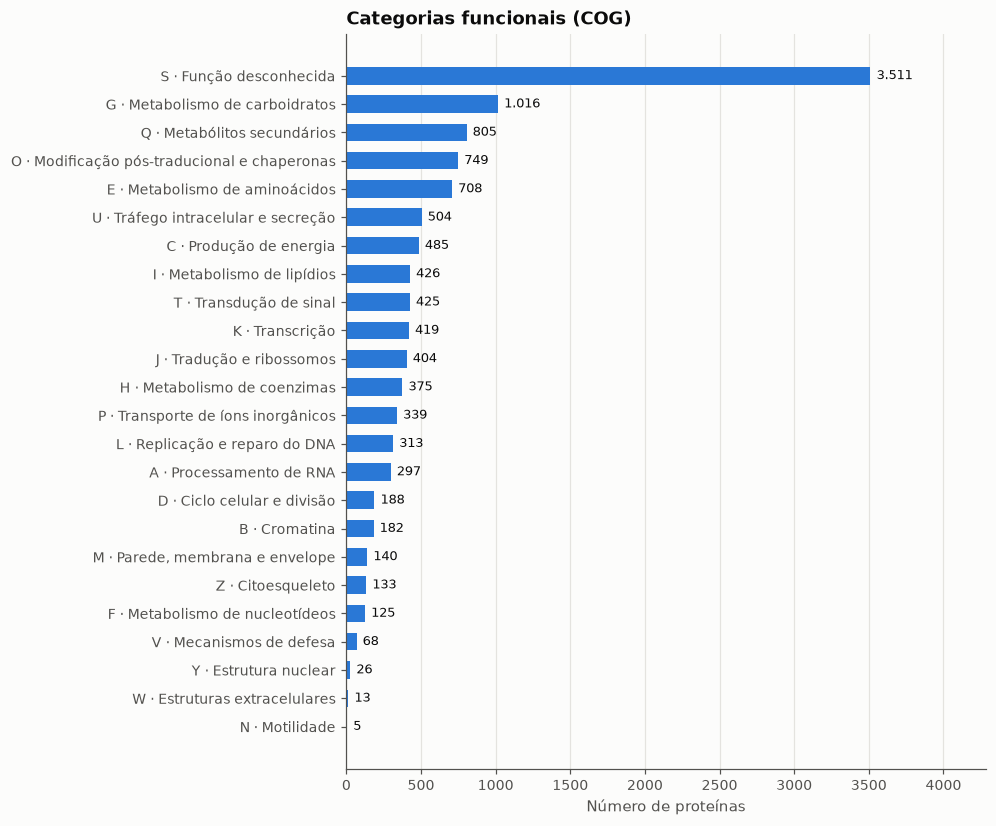

In [31]:
COG = {
    "J": "Tradução e ribossomos", "A": "Processamento de RNA", "K": "Transcrição",
    "L": "Replicação e reparo do DNA", "B": "Cromatina", "D": "Ciclo celular e divisão", "Y": "Estrutura nuclear",
    "V": "Mecanismos de defesa", "T": "Transdução de sinal", "M": "Parede, membrana e envelope",
    "N": "Motilidade", "Z": "Citoesqueleto", "W": "Estruturas extracelulares",
    "U": "Tráfego intracelular e secreção", "O": "Modificação pós-traducional e chaperonas", "X": "Mobiloma",
    "C": "Produção de energia", "G": "Metabolismo de carboidratos", "E": "Metabolismo de aminoácidos",
    "F": "Metabolismo de nucleotídeos", "H": "Metabolismo de coenzimas", "I": "Metabolismo de lipídios",
    "P": "Transporte de íons inorgânicos", "Q": "Metabólitos secundários", "R": "Só função geral prevista",
    "S": "Função desconhecida",
}
letras = U["eggnog_COG_category"].dropna().map(lambda s: [l for l in s if l in COG]).explode()
cog = letras.value_counts().rename(index=lambda l: f"{l} · {COG[l]}")
display(cog.to_frame("proteínas").T)

barras_horizontais(cog.index, cog.values, "Categorias funcionais (COG)", "Número de proteínas", "07_cog")

**Como ler**

- Em proteomas de fungos, a categoria **S** costuma ser a maior: muitos grupos de ortólogos de fungos não têm função
  caracterizada.
- **J** (tradução), **O** (chaperonas e degradação de proteínas) e **D** (ciclo celular) reúnem muitas funções
  essenciais: são categorias ricas em candidatos a alvo.

**Resultado da Ca142**

- **S (função desconhecida) é a maior categoria: 3.511 proteínas,** 32% das 11.040 com categoria.
- **Logo depois vêm G (metabolismo de carboidratos, 1.016) e Q (metabólitos secundários, 805).** Ambas superam C
  (energia, 485) e J (tradução, 404). É o perfil de um fitopatógeno, com um grande arsenal de enzimas para degradar a
  parede da planta e muitos genes de metabolismo secundário (toxinas, pigmentos como a melanina do apressório).
- **O (749), U (504) e I (426)** completam o grupo das grandes. Em O estão chaperonas, proteassoma e ubiquitinação,
  processos essenciais.
- **V (defesa) tem 68 proteínas,** sobretudo transportadores de efluxo (ABC). São os genes ligados à resistência a
  múltiplos fungicidas.

## 9. Vias metabólicas (KEGG)

Contamos quantas proteínas da Ca142 caem em cada via do KEGG. O arquivo do eggNOG-mapper só traz os códigos das vias;
os nomes vêm do serviço público do KEGG (consulta à internet, salva em `data/raw/kegg_vias.tsv`).

**Só as vias que existem em fungos.** O KEGG liga cada KO a todos os mapas em que ele aparece, inclusive mapas de
doenças humanas e de fisiologia animal. No teste, as subunidades da SDH e outras proteínas mitocondriais puseram
"Alzheimer disease", "Parkinson disease" e "Thermogenesis" entre as vias mais frequentes. Para evitar isso, guardamos só
as vias que o KEGG define para pelo menos um de cinco fungos-modelo:

- a levedura *Saccharomyces cerevisiae* (`sce`);
- *Neurospora crassa* (`ncr`), *Fusarium graminearum* (`fgr`) e *Magnaporthe oryzae* (`mgr`), todos
  Sordariomycetes, como *Colletotrichum*;
- *Aspergillus nidulans* (`ani`), rico em metabolismo secundário.

Na primeira versão, só com levedura e *Neurospora*, o filtro retirava vias de metabolismo secundário de fungos, como a
da aflatoxina e a da penicilina.

A lista fica salva em `data/raw/`. Sem internet, o filtro retira os mapas de doenças humanas (`map05…`) e de
fisiologia animal (`map046…` a `map049…`). Os mapas "globais" (como `map01100`, *Metabolic pathways*) também ficam de
fora.

Filtro: vias definidas pelo KEGG para S. cerevisiae, N. crassa, F. graminearum, M. oryzae, A. nidulans (160 vias)
Vias retiradas: 249 de 375. Exemplos: map00072; Primary bile acid biosynthesis; Steroid hormone biosynthesis; map00281; Prodigiosin biosynthesis; Chlorocyclohexane and chlorobenzene degradation


,via,proteínas
eggnog_vias,,
map00230,Purine metabolism,119
map03010,Ribosome,117
map04111,Cell cycle - yeast,105
map00350,Tyrosine metabolism,102
map03013,Nucleocytoplasmic transport,98
map00500,Starch and sucrose metabolism,94
map03040,Spliceosome,94
map00330,Arginine and proline metabolism,89
map04144,Endocytosis,88


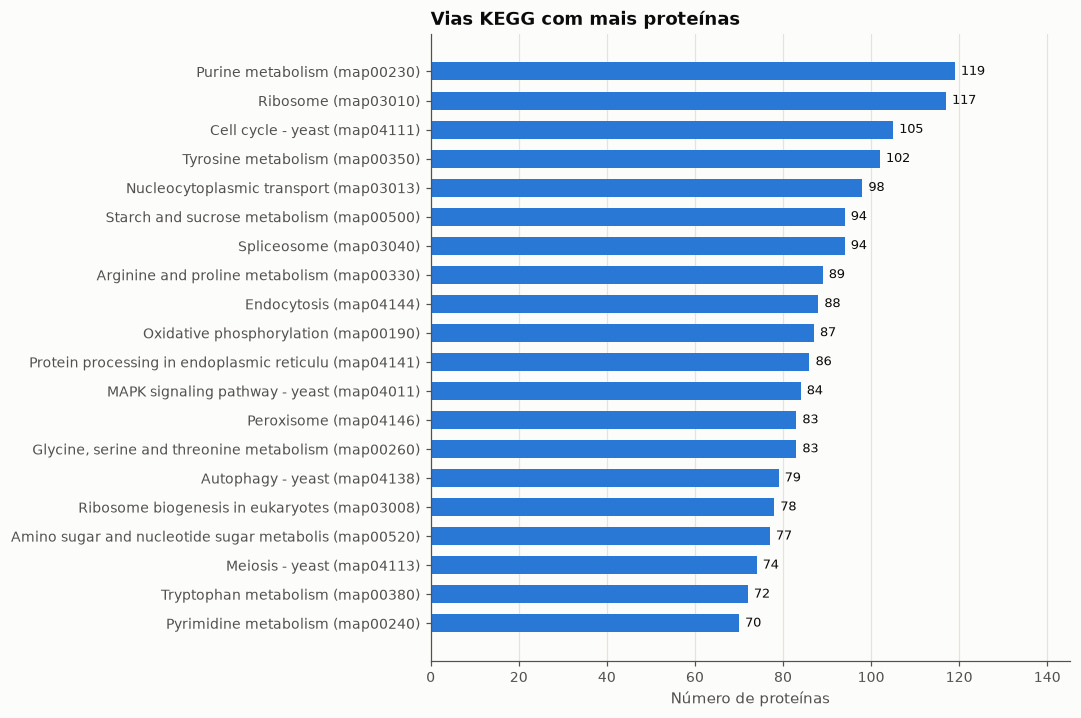

Vias KEGG com pelo menos uma proteína da Ca142: 126


In [32]:
ARQ_KEGG = RAIZ / "data" / "raw" / "kegg_vias.tsv"
if not ARQ_KEGG.exists():
    try:
        with urllib.request.urlopen("https://rest.kegg.jp/list/pathway", timeout=60) as r:
            ARQ_KEGG.write_text(r.read().decode())
    except OSError as erro:
        print("Não foi possível obter os nomes das vias do KEGG:", erro)
nomes_vias = {}
if ARQ_KEGG.exists():
    for linha in ARQ_KEGG.read_text().splitlines():
        partes = linha.split("\t")
        if len(partes) == 2:
            nomes_vias[partes[0].replace("path:", "")] = partes[1]

FUNGOS_KEGG = {"sce": "S. cerevisiae", "ncr": "N. crassa", "fgr": "F. graminearum",
               "mgr": "M. oryzae", "ani": "A. nidulans"}
ARQ_KEGG_FUNGOS = RAIZ / "data" / "raw" / f"kegg_vias_fungos_{'_'.join(FUNGOS_KEGG)}.tsv"
vias_fungos = None
if ARQ_KEGG_FUNGOS.exists():
    vias_fungos = set(ARQ_KEGG_FUNGOS.read_text().split())
else:
    mapas, falhas = set(), []
    for org in FUNGOS_KEGG:
        try:
            with urllib.request.urlopen(f"https://rest.kegg.jp/list/pathway/{org}", timeout=60) as r:
                linhas = r.read().decode().splitlines()
        except OSError:
            falhas.append(org)
            continue
        for linha in linhas:
            if linha.strip():
                mapas.add(re.sub(r"^(?:path:)?[a-z]+", "map", linha.split("\t")[0]))
    if falhas:
        print("O KEGG não respondeu para:", ", ".join(falhas), "(a lista não foi salva; tente de novo depois)")
    if mapas:
        vias_fungos = mapas
        if not falhas:
            ARQ_KEGG_FUNGOS.write_text("\n".join(sorted(mapas)) + "\n")

vias = U["eggnog_vias"].dropna().str.split(",").explode()
vias = vias[~vias.str.match(r"map01[12]\d\d")]                 # mapas globais e de visão geral
antes = vias.nunique()
if vias_fungos:
    retiradas = sorted(set(vias) - vias_fungos)
    vias = vias[vias.isin(vias_fungos)]
    print(f"Filtro: vias definidas pelo KEGG para {', '.join(FUNGOS_KEGG.values())} ({len(vias_fungos)} vias)")
else:
    retiradas = sorted(set(vias[vias.str.match(r"map0(?:5|4[6-9])")]))
    vias = vias[~vias.isin(retiradas)]
    print("Filtro: sem a lista de fungos; retirados os mapas de doenças humanas e fisiologia animal")
print(f"Vias retiradas: {len(retiradas)} de {antes}. Exemplos: "
      + "; ".join(nomes_vias.get(v, v) for v in retiradas[:6]))
contagem_vias = vias.value_counts()
top_vias = contagem_vias.head(20).to_frame("proteínas")
top_vias.insert(0, "via", [nomes_vias.get(v, "") for v in top_vias.index])
display(top_vias)

rotulos = [f"{nomes_vias[v][:42]} ({v})" if v in nomes_vias else v for v in top_vias.index]
barras_horizontais(rotulos, top_vias["proteínas"].tolist(), "Vias KEGG com mais proteínas",
                   "Número de proteínas", "07_kegg")
print(f"Vias KEGG com pelo menos uma proteína da Ca142: {contagem_vias.size}")

**Como ler**

- A primeira linha da saída diz quantas vias o filtro de fungos retirou, com exemplos. Devem ser mapas de doenças
  humanas e de fisiologia animal. Códigos sem nome (como `map00072` e `map00281`) devem ser mapas que o KEGG retirou ou
  renumerou depois de 2019, ano do banco do eggNOG-mapper.
- Para ver os genes de qualquer via:
  `U[U["eggnog_vias"].str.contains("map00100", na=False)][["locus_tag", "nome_consenso", "eggnog_Preferred_name", "n_alertas"]]`.

**Resultado da Ca142** (execução com o filtro de levedura e *Neurospora*; com cinco fungos, os números mudam pouco)

- **As proteínas da Ca142 caem em 120 vias de fungos.** O filtro retirou 255 das 375 vias encontradas.
- **O topo mistura processos centrais e metabolismo:**
  - processos centrais: ribossomo (117), ciclo celular (105), transporte núcleo-citoplasma (98), spliceossomo (94),
    endocitose (88), processamento de proteínas no retículo (86);
  - metabolismo: purinas (119), tirosina (102), amido e sacarose (94), arginina e prolina (89).
- **Fosforilação oxidativa (87 proteínas)** é a via da SDH (complexo II). As vias dos outros alvos clássicos, como a
  biossíntese de esteroides (`map00100`, ergosterol) e o metabolismo de amino-açúcares (`map00520`, quitina; 77),
  aparecem mais abaixo ou no topo da lista.
- **Atenção a vias infladas por famílias de enzimas promíscuas.** "Tyrosine metabolism" está alta porque reúne
  desidrogenases e oxidases que também aparecem em muitas outras vias, e não porque o fungo dependa especialmente
  dela. O número de proteínas numa via mede o tamanho das famílias, não a importância da via.

## 10. Alvos clássicos de fungicidas e maquinaria de RNAi

Os fungicidas mais usados agem sobre um punhado de proteínas essenciais. Os genes dessas proteínas são candidatos
naturais a alvo de RNAi: a função é essencial e já foi validada no campo.

| Proteína | KO | Classe de fungicida |
|---|---|---|
| CYP51 / ERG11 (lanosterol 14α-desmetilase) | K05917 | triazóis (DMI) |
| Esqualeno monooxigenase (ERG1) | K00511 | alilaminas |
| SdhA, SdhB, SdhC, SdhD (succinato desidrogenase) | K00234 a K00237 | carboxamidas (SDHI) |
| β-tubulina | K07375 | benzimidazóis (MBC) |
| Quitina sintase | K00698 | polioxinas |
| β-1,3-glucana sintase (FKS) | K00706 | equinocandinas |

O alvo das estrobilurinas (QoI), o citocromo *b*, não aparece: é codificado no genoma **mitocondrial**, que os autores
separaram da montagem nuclear.

**Como os genes são identificados.** Cada proteína é procurada por três critérios, e a coluna `criterio` diz qual
encontrou o gene:

1. **KO:** o código do KEGG;
2. **nome curto:** o `Preferred_name` do eggNOG-mapper (por exemplo, `ERG11`, `DCL2`);
3. **descrição:** um padrão de texto no produto original ou na descrição do eggNOG-mapper.

Descrições de proteínas acessórias (chaperonas, fatores de montagem, ativadores) não contam no terceiro critério.

**Descarte de outros genes.** A primeira execução completa mostrou genes que receberam o KO de um alvo junto com o de
outra proteína:

- a cetopantoato redutase **PAN5** tinha os KOs K00077 e K00511 (este último, o da ERG1);
- a helicase de RNA **MTR4** tinha os KOs K12598 e K11593 (este último, o das Argonautas).

Agora, um gene encontrado é **descartado** quando seu nome curto é de outra proteína e (a) ele tem mais de um KO, ou
(b) foi encontrado só pela descrição. A coluna `descarte` diz o motivo; os descartados aparecem no fim da tabela, mas
não entram na contagem.

**O número de cópias importa para o RNAi.** Com uma cópia, o silenciamento atinge toda a função. Com várias, uma
cópia não silenciada pode compensar, a menos que o dsRNA seja desenhado sobre um trecho comum a todas.

In [33]:
# (proteína, KOs, nomes curtos aceitos, padrão na descrição ou None)
ALVOS = [
    ("CYP51 / ERG11", {"K05917"}, {"ERG11", "CYP51", "CYP51A", "CYP51B", "CYP51C"},
     r"14-?alpha-?(?:sterol )?demethylase|\bCYP51"),
    ("ERG1 (esqualeno monooxigenase)", {"K00511"}, {"ERG1"}, r"squalene (?:mono)?oxygenase|squalene epoxidase"),
    ("SdhA", {"K00234"}, {"SDH1"}, None),
    ("SdhB", {"K00235"}, {"SDH2"}, None),
    ("SdhC", {"K00236"}, {"SDH3"}, None),
    ("SdhD", {"K00237"}, {"SDH4"}, None),
    ("β-tubulina", {"K07375"}, {"TUB2", "BENA", "TUBB", "TUBC", "BML"}, r"beta[- ]?tubulin|tubulin beta"),
    ("quitina sintase", {"K00698"}, {"CHS1", "CHS2", "CHS3", "CHSA", "CHSB", "CHSC", "CHSD", "CHSE", "CHSG",
                                     "CSMA", "CSMB"}, r"chitin synthase"),
    ("β-1,3-glucana sintase", {"K00706"}, {"FKS1", "FKS2", "GSC2"}, r"1,3-beta-glucan synthase|beta-1,3-glucan synthase"),
]
RNAI = [
    ("Dicer", {"K11592"}, {"DCL1", "DCL2"}, r"\bdicer"),
    ("Argonauta", {"K11593"}, {"AGO1", "AGO2", "QDE2", "SMS2"}, r"argonaute family|argonaute protein|\bpiwi"),
    ("RdRP", {"K11699"}, {"RDP1", "QDE1", "RDR1"}, r"RNA-(?:dependent|directed) RNA polymerase"),
]
EXCLUIR = r"chaperone|assembly factor|export|activator|regulator"
COLS_ALVO = ["proteina_alvo", "criterio", "descarte", "locus_tag", "nome_consenso", "eggnog_Preferred_name",
             "eggnog_ko", "tam_proteina", "n_exons", "n_alertas", "busco_status", "dist_bloco_rip",
             "conjunto_confiavel"]

def identificar(definicoes):
    """Genes de cada proteína (KO, nome curto ou descrição), com o critério e o motivo de descarte, se houver."""
    kos = U["eggnog_ko"].fillna("").str.split(",").map(lambda ks: {k for k in ks if k})
    nomes = U["eggnog_Preferred_name"].fillna("").str.upper().str.replace("-", "", regex=False)
    texto = U["produto"].fillna("") + " | " + U["eggnog_Description"].fillna("")
    acessoria = texto.str.contains(EXCLUIR, case=False, regex=True)
    partes = []
    for proteina, ko_alvo, nomes_alvo, padrao in definicoes:
        por_ko = kos.map(lambda ks: bool(ks & ko_alvo))
        por_nome = nomes.isin(nomes_alvo)
        por_texto = (texto.str.contains(padrao, case=False, regex=True) & ~acessoria) if padrao else por_ko & False
        achou = (por_ko | por_nome | por_texto).to_numpy()
        criterio = np.select([por_ko, por_nome], ["KO", "nome curto"], default="descrição")
        outro_nome = (nomes != "") & ~por_nome
        conflito = outro_nome & ((kos.map(len) > 1) | (criterio == "descrição"))
        motivo = np.where(conflito, "nome curto de outra proteína: " + U["eggnog_Preferred_name"].fillna(""), "")
        partes.append(U[achou].assign(proteina_alvo=proteina, criterio=criterio[achou], descarte=motivo[achou]))
    tabela = pd.concat(partes)[COLS_ALVO]
    ordem = {d[0]: i for i, d in enumerate(definicoes)}
    return tabela.sort_values(["descarte", "proteina_alvo", "locus_tag"], key=lambda s: s.map(ordem) if s.name == "proteina_alvo" else s)

def contar(tabela, definicoes):
    ordem = [d[0] for d in definicoes]
    validos = tabela[tabela["descarte"] == ""]
    resumo = validos.groupby("proteina_alvo")["criterio"].value_counts().unstack(fill_value=0)
    resumo = resumo.reindex(index=ordem, columns=["KO", "nome curto", "descrição"], fill_value=0)
    resumo.insert(0, "cópias", resumo.sum(axis=1))
    resumo["descartados"] = tabela[tabela["descarte"] != ""].groupby("proteina_alvo").size().reindex(ordem, fill_value=0)
    return resumo

alvos = identificar(ALVOS)
resumo_alvos = contar(alvos, ALVOS)
copias = resumo_alvos["cópias"]
display(resumo_alvos)
display(alvos)

criterio,cópias,KO,nome curto,descrição,descartados
proteina_alvo,,,,,
CYP51 / ERG11,4,4,0,0,0
ERG1 (esqualeno monooxigenase),1,1,0,0,1
SdhA,1,1,0,0,0
SdhB,1,1,0,0,0
SdhC,1,1,0,0,0
SdhD,1,1,0,0,0
β-tubulina,2,0,0,2,0
quitina sintase,10,9,0,1,0
"β-1,3-glucana sintase",1,1,0,0,0


,proteina_alvo,criterio,descarte,locus_tag,nome_consenso,eggnog_Preferred_name,eggnog_ko,tam_proteina,n_exons,n_alertas,busco_status,dist_bloco_rip,conjunto_confiavel
3417,CYP51 / ERG11,KO,,CABS02_03419,14-alpha sterol demethylase Cyp51A,ERG11,K05917,519,3,0,NaN,295405.0,False
5497,CYP51 / ERG11,KO,,CABS02_05499,cytochrome P450 6A1,NaN,K05917,527,3,0,NaN,215795.0,False
10081,CYP51 / ERG11,KO,,CABS02_10052,eburicol 14-alpha-demethylase,ERG11,K05917,526,3,0,Complete,NaN,True
10491,CYP51 / ERG11,KO,,CABS02_10462,Cytochrome P450,NaN,K05917,479,4,0,NaN,15971.0,False
7163,ERG1 (esqualeno monooxigenase),KO,,CABS02_07167,squalene epoxidase,ERG1,K00511,499,1,0,Complete,NaN,True
14284,SdhA,KO,,CABS02_14283,succinate dehydrogenase,SDH1,K00234,643,4,0,Complete,NaN,True
14283,SdhB,KO,,CABS02_14282,succinate dehydrogenase iron-sulfur subunit,SDH2,K00235,277,3,0,Complete,NaN,True
6922,SdhC,KO,,CABS02_06926,succinate dehydrogenase cytochrome b subunit,SDH3,K00236,188,3,0,Complete,2410.0,True
11946,SdhD,KO,,CABS02_11911,CybS protein,SDH4,"K00237,K17791",175,3,0,Complete,NaN,True
14957,β-tubulina,descrição,,CABS02_14956,beta-tubulin cofactor d,NaN,K21767,1070,2,0,Complete,NaN,True


In [34]:
rnai = identificar(RNAI)
print("Maquinaria de RNAi:")
display(contar(rnai, RNAI))

fora = controles_rnai[~controles_rnai["locus_tag"].isin(rnai.loc[rnai["descarte"] == "", "locus_tag"])]
print("Controles de RNAi da seção 3 que não entraram:", ", ".join(fora["locus_tag"]) or "nenhum")
rnai

Maquinaria de RNAi:


criterio,cópias,KO,nome curto,descrição,descartados
proteina_alvo,,,,,
Dicer,2,1,1,0,0
Argonauta,4,4,0,0,1
RdRP,4,2,0,2,0


Controles de RNAi da seção 3 que não entraram: CABS02_02578, CABS02_04245, CABS02_07952


,proteina_alvo,criterio,descarte,locus_tag,nome_consenso,eggnog_Preferred_name,eggnog_ko,tam_proteina,n_exons,n_alertas,busco_status,dist_bloco_rip,conjunto_confiavel
4411,Dicer,nome curto,,CABS02_04413,RNase3 domain-containing protein,DCL2,NaN,1442,6,0,Complete,360650.0,True
5550,Dicer,KO,,CABS02_05552,RNase3 domain-containing protein,dcl1,K11592,1606,3,0,Complete,146681.0,True
10962,Argonauta,KO,,CABS02_10933,piwi domain-containing protein,NaN,K11593,1109,2,0,Duplicated,84458.0,False
13717,Argonauta,KO,,CABS02_13697,piwi domain-containing protein,ago1,K11593,974,2,0,Complete,NaN,True
14426,Argonauta,KO,,CABS02_14425,piwi domain-containing protein,NaN,K11593,1075,2,0,Duplicated,NaN,False
14585,Argonauta,KO,,CABS02_14584,piwi domain-containing protein,NaN,K11593,1048,3,0,Duplicated,NaN,False
4671,RdRP,KO,,CABS02_04673,RNA-dependent RNA polymerase,NaN,K11699,1314,3,0,NaN,279385.0,False
10286,RdRP,descrição,,CABS02_10257,RNA-directed RNA polymerase,NaN,NaN,1360,3,0,Complete,NaN,True
11601,RdRP,KO,,CABS02_11572,RNA-dependent RNA polymerase,NaN,K11699,1254,2,0,Complete,NaN,True
14425,RdRP,descrição,,CABS02_14424,RNA-directed RNA polymerase,NaN,NaN,1409,3,0,NaN,NaN,False


**Como ler**

- **Primeira tabela:** quantas cópias de cada proteína a Ca142 tem, por qual critério elas foram encontradas e quantos
  genes foram descartados.
- **Segunda tabela:** os genes, com os alertas de modelo, a distância ao bloco de RIP e se estão no conjunto
  confiável. Os descartados ficam no fim, com o motivo.

**Resultado da Ca142** (primeira execução completa; os descartes já estão aplicados no texto)

| Proteína | Cópias | Observação |
|---|---|---|
| SdhA, SdhB, SdhC, SdhD | 1 cada | todas pelo KO, sem alertas, no conjunto confiável |
| CYP51 | 4 pelo KO | 2 são CYP51 de fato; 2 provavelmente são outros citocromos P450 (seção 10.1) |
| ERG1 | 1 | a PAN5 (cetopantoato redutase) é descartada |
| quitina sintase | 10 | 9 pelo KO, 1 só pela descrição (CABS02_13645, a conferir) |
| β-1,3-glucana sintase (FKS1) | 1 | tem 1 alerta de modelo e está fora do conjunto confiável |
| β-tubulina | 0 pelo KO | agora também pela descrição do produto original |
| Dicer | 2 | a DCR2 (fosfoesterase de levedura) não conta mais como Dicer |
| Argonauta | 4 | a MTR4 (helicase de RNA) é descartada |
| RdRP | 4 | 2 pelo KO, 2 pela descrição |

- **A SDH é um alvo de manual para RNAi:** as quatro subunidades têm cópia única, nenhum alerta de modelo e estão no
  conjunto confiável. A SdhA (CABS02_14283) e a SdhB (CABS02_14282) são genes vizinhos.
- **A FKS1 (CABS02_04979) também tem cópia única,** mas um alerta de modelo; confira qual antes de desenhar o dsRNA.
- **β-tubulina sem KO** é estranho: todo fungo tem pelo menos uma. A nova versão procura também "beta-tubulin" no
  produto original. Se continuar zero, veja o que o eggNOG-mapper atribuiu aos genes com "tubulin" no produto:
  `U[U["produto"].str.contains("tubulin", case=False, na=False)][["locus_tag", "produto", "eggnog_Preferred_name", "eggnog_ko"]]`.
- **As quitina sintases formam uma família grande, de classes diferentes.** CABS02_05645 e CABS02_05646 são vizinhas e
  longas (1.785 e 1.869 aa). Devem ser as quitina sintases com domínio de miosina (classes V e VII), que em outros
  fungos também ficam lado a lado no genoma.
- **A maquinaria de RNAi fica em 2 Dicer, 4 Argonautas e 4 RdRP,** como no teste. Três das quatro Argonautas aparecem
  como "Duplicated" no BUSCO, ou seja, ligadas ao mesmo gene do conjunto de referência.

### 10.1 Identidade entre as cópias

Quando um alvo tem várias cópias, a pergunta é: são versões da mesma proteína, ou proteínas diferentes que receberam
o mesmo KO? Alinhamos as proteínas duas a duas (alinhamento local, BLOSUM62) e calculamos a **identidade**: a
porcentagem de aminoácidos iguais, em relação à proteína mais curta.

Referências para ler a matriz:

- **acima de ~40%:** mesma família de proteínas, com função provavelmente igual ou parecida (por exemplo, CYP51A e
  CYP51B);
- **20% a 30%:** parentesco distante. Citocromos P450 de famílias diferentes, por exemplo, ficam nessa faixa;
- **abaixo de 20%:** sem parentesco detectável neste alinhamento.

Para o RNAi, a identidade de proteína é só uma primeira pista. Se o dsRNA atinge mais de uma cópia depende da
identidade das sequências de nucleotídeos, em trechos contínuos de pelo menos uns 20 nt. Essa conferência vem na
etapa de desenho do dsRNA.

In [35]:
from Bio import Align
from Bio.Align import substitution_matrices

SEQS = {r.id: str(r.seq).rstrip("*") for r in SeqIO.parse(ARQ_PROT, "fasta")}
ALINHADOR = Align.PairwiseAligner()
ALINHADOR.mode = "local"
ALINHADOR.substitution_matrix = substitution_matrices.load("BLOSUM62")
ALINHADOR.open_gap_score, ALINHADOR.extend_gap_score = -10, -0.5

def identidade(a, b):
    """% de aminoácidos idênticos no alinhamento local, em relação à proteína mais curta."""
    aln = ALINHADOR.align(a, b)[0]
    iguais = sum(a[i] == b[j]
                 for (ia, fa), (ib, fb) in zip(*aln.aligned)
                 for i, j in zip(range(ia, fa), range(ib, fb)))
    return 100 * iguais / min(len(a), len(b))

def matriz_identidade(tabela, proteina):
    genes = tabela[(tabela["proteina_alvo"] == proteina) & (tabela["descarte"] == "")]
    pids = U.set_index("locus_tag").loc[genes["locus_tag"], "protein_id"]
    rotulos = [f"{lt} ({nome})" if isinstance(nome, str) else lt
               for lt, nome in zip(genes["locus_tag"], genes["eggnog_Preferred_name"])]
    m = pd.DataFrame(100.0, index=rotulos, columns=genes["locus_tag"].tolist())
    for i, pi in enumerate(pids):
        for j, pj in enumerate(pids):
            if j > i:
                m.iloc[i, j] = m.iloc[j, i] = identidade(SEQS[pi], SEQS[pj])
    return m.round(0).astype(int)

for tabela, definicoes in ((alvos, ALVOS), (rnai, RNAI)):
    for proteina in [d[0] for d in definicoes]:
        if ((tabela["proteina_alvo"] == proteina) & (tabela["descarte"] == "")).sum() >= 2:
            print(f"\n{proteina}: identidade entre as cópias (%)")
            display(matriz_identidade(tabela, proteina))


CYP51 / ERG11: identidade entre as cópias (%)


,CABS02_03419,CABS02_05499,CABS02_10052,CABS02_10462
CABS02_03419 (ERG11),100,25,53,22
CABS02_05499,25,100,22,24
CABS02_10052 (ERG11),53,22,100,23
CABS02_10462,22,24,23,100



β-tubulina: identidade entre as cópias (%)


,CABS02_14956,CABS02_15494
CABS02_14956,100,22
CABS02_15494,22,100



quitina sintase: identidade entre as cópias (%)


,CABS02_05645,CABS02_05646,CABS02_05945,CABS02_06992,CABS02_09346,CABS02_10608,CABS02_11951,CABS02_12363,CABS02_13645,CABS02_14362
CABS02_05645,100,36,19,20,20,21,14,18,21,29
CABS02_05646,36,100,13,20,19,24,13,23,16,28
CABS02_05945 (CHS2),19,13,100,25,13,25,31,45,23,15
CABS02_06992,20,20,25,100,18,25,21,20,22,16
CABS02_09346 (chsD),20,19,13,18,100,20,12,15,23,15
CABS02_10608,21,24,25,25,20,100,24,19,22,21
CABS02_11951 (CHS3),14,13,31,21,12,24,100,41,19,15
CABS02_12363 (CHS2),18,23,45,20,15,19,41,100,21,19
CABS02_13645,21,16,23,22,23,22,19,21,100,15
CABS02_14362 (CHS3),29,28,15,16,15,21,15,19,15,100


... (2 outputs left out)


Argonauta: identidade entre as cópias (%)


,CABS02_10933,CABS02_13697,CABS02_14425,CABS02_14584
CABS02_10933,100,29,61,63
CABS02_13697 (ago1),29,100,29,30
CABS02_14425,61,29,100,77
CABS02_14584,63,30,77,100



RdRP: identidade entre as cópias (%)


,CABS02_04673,CABS02_10257,CABS02_11572,CABS02_14424
CABS02_04673,100,19,29,16
CABS02_10257,19,100,19,48
CABS02_11572,29,19,100,14
CABS02_14424,16,48,14,100


**Como ler**

- **CYP51:** as duas cópias com nome `ERG11` (CABS02_03419, "Cyp51A", e CABS02_10052, "eburicol 14-alpha-demethylase",
  provavelmente a CYP51B) devem ter identidade alta entre si. Fungos do gênero costumam ter essas duas. Se as outras
  duas (CABS02_05499, "cytochrome P450 6A1", e CABS02_10462, "Cytochrome P450") ficarem na faixa de 20% a 30% com
  elas, são citocromos P450 de outras famílias. Nesse caso, receberam o KO da CYP51 porque o grupo de ortólogos no
  nível Fungi é amplo demais.
- **Quitina sintases:** espere blocos de identidade alta dentro de cada classe e baixa entre classes. A CABS02_13645,
  achada só pela descrição ("chitin synthase activity", 500 aa), é suspeita se não tiver identidade razoável com
  nenhuma outra.
- **Argonautas e RdRP:** cópias com identidade alta entre si podem ser silenciadas pelo mesmo dsRNA. Cópias muito
  diferentes devem ter funções distintas (em *Neurospora*, por exemplo, QDE-2 e SMS-2 atuam em vias diferentes de
  silenciamento).

## 11. Integração com a análise exploratória

O caderno 06 mostrou que, quanto mais perto de um bloco com assinatura de RIP, menor a proporção de genes ligados a um
BUSCO. O BUSCO só olha um conjunto de genes muito conservados. O eggNOG-mapper permite repetir o teste com todos os
genes: **a proporção de genes com ortólogo conhecido também cai perto dos blocos?**

Também comparamos os genes do conjunto confiável (caderno 06) com o resto.

In [36]:
if U["dist_bloco_rip"].notna().any():
    FAIXAS = ["toca um bloco", "até 2 kb", "2 a 10 kb", "10 a 50 kb", "mais de 50 kb ou scaffold sem bloco"]
    faixa = pd.cut(U["dist_bloco_rip"].fillna(np.inf), [-1, 0, 2_000, 10_000, 50_000, np.inf], labels=FAIXAS)
    por_dist = U.groupby(faixa, observed=False).agg(
        genes=("locus_tag", "size"),
        com_ortologo=("tem_ortologo", "mean"),
        descricao_informativa=("desc_informativa", "mean"),
        com_ko=("eggnog_ko", lambda s: s.notna().mean()))
    for col in ("com_ortologo", "descricao_informativa", "com_ko"):
        por_dist[col] = (100 * por_dist[col]).round(1)
    por_dist.columns = ["genes", "% com ortólogo", "% com descrição informativa", "% com KO"]
    por_dist.index.name = "distância ao bloco de RIP"
    display(por_dist)
else:
    print("Sem a coluna dist_bloco_rip; rode de novo o caderno 06 (versão revisada).")

confiavel = U.groupby(U["conjunto_confiavel"].map({True: "conjunto confiável", False: "demais genes"})).agg(
    genes=("locus_tag", "size"),
    com_ortologo=("tem_ortologo", "mean"),
    com_ko=("eggnog_ko", lambda s: s.notna().mean()),
    com_via=("eggnog_vias", lambda s: s.notna().mean()))
for col in ("com_ortologo", "com_ko", "com_via"):
    confiavel[col] = (100 * confiavel[col]).round(1)
confiavel.columns = ["genes", "% com ortólogo", "% com KO", "% com via KEGG"]
confiavel

,genes,% com ortólogo,% com descrição informativa,% com KO
distância ao bloco de RIP,,,,
toca um bloco,55,94.5,70.9,20.0
até 2 kb,273,93.4,66.7,22.0
2 a 10 kb,774,90.7,68.9,27.9
10 a 50 kb,2751,90.8,69.9,29.3
mais de 50 kb ou scaffold sem bloco,11646,88.2,68.2,32.2


,genes,% com ortólogo,% com KO,% com via KEGG
conjunto_confiavel,,,,
conjunto confiável,5384,100.0,56.1,35.5
demais genes,10115,83.0,18.0,11.3


**Como ler**

- **Primeira tabela:** a porcentagem de genes com ortólogo, com descrição informativa e com KO, conforme a distância
  ao bloco de RIP mais próximo.
- **Segunda tabela:** o conjunto confiável do caderno 06 comparado aos demais genes.

**Resultado da Ca142**

- **Perto dos blocos de RIP, a proporção de genes com ortólogo é *maior*, não menor:** 94,5% nos 55 genes que tocam um
  bloco e 93,4% nos 273 a até 2 kb, contra 88,2% nos genes longe dos blocos. A hipótese da seção não se confirmou como
  formulada.
- **Já a proporção com KO cai perto dos blocos:** 20% nos que tocam e 22% até 2 kb, contra 32% longe deles. Os genes
  perto das regiões repetitivas têm parentes em outros fungos, mas raramente uma função metabólica ou celular
  definida.
- **Os dois resultados se conciliam se parte desses genes vier de elementos transponíveis.** Transposases e
  transcriptases reversas têm ortólogos em muitos fungos, e por isso aparecem com "ortólogo", mas quase nunca têm KO.
  Isso também explica o resultado do caderno 06: perto dos blocos há menos genes BUSCO, que são genes essenciais e
  conservados. A célula seguinte testa essa explicação.
- **O conjunto confiável tem 100% de genes com ortólogo,** como esperado: são genes de BUSCO. Também tem três vezes
  mais genes com KO que o restante do proteoma (56% contra 18%). É nele que estão os genes de função celular básica,
  os melhores candidatos a alvo.

In [37]:
PADRAO_TE = (r"transpos|reverse transcriptase|integrase|retrotranspos|\bgag\b|ribonuclease H|\bRNase H|helitron"
             r"|\bTc1\b|mariner|\bRVT_|\brve\b|DDE_|Tnp|Retrotrans")
texto_te = (U["produto"].fillna("") + " | " + U["eggnog_Description"].fillna("") + " | " + U["eggnog_PFAMs"].fillna(""))
U_te = U.assign(parece_te=texto_te.str.contains(PADRAO_TE, case=False, regex=True),
                perto_rip=U["dist_bloco_rip"].notna() & (U["dist_bloco_rip"] <= 2_000))

te = U_te.groupby(U_te["perto_rip"].map({True: "até 2 kb de um bloco de RIP", False: "mais longe ou sem bloco"})).agg(
    genes=("locus_tag", "size"), parecem_te=("parece_te", "sum"), pct=("parece_te", "mean"))
te["pct"] = (100 * te["pct"]).round(1)
te.columns = ["genes", "com sinal de elemento transponível", "%"]
display(te)

print("Descrições mais frequentes entre os genes até 2 kb de um bloco de RIP:")
U_te[U_te["perto_rip"]]["eggnog_Description"].fillna("(sem descrição)").value_counts().head(15).to_frame("genes")

,genes,com sinal de elemento transponível,%
perto_rip,,,
até 2 kb de um bloco de RIP,328,4,1.2
mais longe ou sem bloco,15171,53,0.3


Descrições mais frequentes entre os genes até 2 kb de um bloco de RIP:


,genes
eggnog_Description,
(sem descrição),95
Heterokaryon incompatibility protein (HET),5
FAD binding domain,4
Protein of unknown function (DUF3435),4
Major facilitator superfamily transporter,4
Major Facilitator Superfamily,4
Belongs to the major facilitator superfamily. Sugar transporter (TC 2.A.1.1) family,3
Enoyl-(Acyl carrier protein) reductase,3
FAD binding domain-containing protein,3


**Como ler**

- **Primeira tabela:** a porcentagem de genes com sinal de elemento transponível, perto e longe dos blocos de RIP. O
  sinal é uma palavra-chave no produto, na descrição ou nos domínios Pfam: transposase, transcriptase reversa,
  integrase, RNase H, gag e outras.
- Se a porcentagem perto dos blocos for bem maior, a explicação da seção anterior se confirma: parte dos "genes"
  perto dos blocos são restos de transposons que o anotador tratou como genes.
- **Esses genes devem sair da lista de candidatos a alvo,** mesmo com ortólogo: não têm função no fungo, e transposons
  costumam ter muitas cópias espalhadas pelo genoma.
- **A segunda tabela** mostra as descrições mais comuns perto dos blocos, para conferir o que mais se concentra ali
  (por exemplo, fatores de transcrição ou proteínas HET).

## 12. Tabelas salvas

| Arquivo | Conteúdo |
|---|---|
| `results/eggnog/ca142.emapper.annotations` | a saída original do eggNOG-mapper |
| `data/processed/ca142_eggnog.tsv` | a mesma saída, lida e organizada (uma linha por proteína anotada) |
| `data/processed/ca142_genes_anotados.tsv` | a tabela final de genes do caderno 06 com as colunas do eggNOG-mapper e o nome de consenso |

In [38]:
emap.to_csv(DIR_PROC / "ca142_eggnog.tsv", sep="\t", index=False)
COLS_EGGNOG = ["eggnog_seed_ortholog", "eggnog_evalue", "eggnog_max_annot_lvl", "eggnog_COG_category",
               "eggnog_Description", "eggnog_Preferred_name", "eggnog_GOs", "eggnog_EC", "eggnog_ko",
               "eggnog_vias", "eggnog_CAZy", "eggnog_PFAMs"]
saida = anot[list(final.columns) + ["nome_consenso", "fonte_nome"] + COLS_EGGNOG]
saida.to_csv(DIR_PROC / "ca142_genes_anotados.tsv", sep="\t", index=False)
print(f"ca142_eggnog.tsv          {fmt(len(emap)):>7s} linhas")
print(f"ca142_genes_anotados.tsv  {fmt(len(saida)):>7s} linhas, {saida.shape[1]} colunas")

ca142_eggnog.tsv           13.783 linhas
ca142_genes_anotados.tsv   15.499 linhas, 42 colunas


## 13. Síntese e próximos passos

In [39]:
sintese = pd.Series(dtype="object", data={
    "eggNOG-mapper": VERSAO,
    "Escopo taxonômico": TAX_SCOPE,
    "Proteínas analisadas": fmt(len(U)) + ("" if completo else " (teste)"),
    "Com ortólogo no eggNOG": f"{100 * U['tem_ortologo'].mean():.1f}%",
    "Com descrição informativa": f"{100 * U['desc_informativa'].mean():.1f}%",
    "Com KO (KEGG)": f"{100 * U['eggnog_ko'].notna().mean():.1f}%",
    "Com via KEGG": f"{100 * U['eggnog_vias'].notna().mean():.1f}%",
    "Hipotéticas que ganharam descrição": f"{fmt(hip['desc_informativa'].sum())} de {fmt(len(hip))}",
    "Genes sem função atribuída (consenso)": f"{100 * (U['fonte_nome'] == 'sem função atribuída').mean():.1f}%",
    "Alvos clássicos encontrados": f"{int((copias > 0).sum())} de {len(copias)}",
})
sintese.to_frame("Ca142")

,Ca142
eggNOG-mapper,2.1.15
Escopo taxonômico,auto
Proteínas analisadas,15.499
Com ortólogo no eggNOG,88.9%
Com descrição informativa,68.5%
Com KO (KEGG),31.2%
Com via KEGG,19.7%
Hipotéticas que ganharam descrição,3.464 de 8.229
Genes sem função atribuída (consenso),27.8%
Alvos clássicos encontrados,9 de 9


**Respostas**

1. **Quanto do proteoma tem ortólogo conhecido?** 88,9% (13.783 de 15.499 proteínas). 71,2% receberam descrição
   funcional, e 31,2% um KO do KEGG.
2. **Quantas proteínas hipotéticas ganharam função?** 3.464 das 8.229 (42%). Somando a anotação original, o
   eggNOG-mapper e o BUSCO, 72% dos genes têm agora um nome de função; 4.308 (27,8%) continuam sem.
3. **Que funções predominam?** Depois de "função desconhecida" (3.511), vêm metabolismo de carboidratos (1.016) e
   metabólitos secundários (805), à frente de energia e tradução: o perfil de um fitopatógeno. Entre as vias de
   fungos, as maiores são processos centrais (ribossomo, ciclo celular, spliceossomo) e o metabolismo de purinas,
   aminoácidos e açúcares.
4. **Os alvos clássicos de fungicidas estão lá, e em quantas cópias?**
   - SDH (4 subunidades), ERG1 e FKS1: cópia única;
   - CYP51: 2 cópias (as outras 2 a confirmar na seção 10.1);
   - quitina sintase: cerca de 9 cópias, de classes diferentes;
   - β-tubulina: a confirmar com a nova busca.
   A maquinaria de RNAi tem 2 Dicer, 4 Argonautas e 4 RdRP.
5. **Perto dos blocos de RIP há menos genes conhecidos?** Não exatamente. Há tantos ou mais genes com ortólogo, mas
   menos com função definida (KO). A seção 11 testa se isso se deve a restos de transposons.

**Para o projeto de RNAi**

- **A SDH continua sendo um bom alvo inicial:** quatro subunidades de cópia única, sem alertas de modelo e no
  conjunto confiável. Para começar, a SdhB (CABS02_14282, 277 aa) ou a SdhC (CABS02_06926, 188 aa) são as mais curtas
  e fáceis de cobrir com um dsRNA.
- **ERG1 e FKS1 também são de cópia única e são essenciais.** Valem como segundos alvos, depois de conferir o alerta
  de modelo da FKS1.
- **CYP51 e quitina sintase têm várias cópias.** Para silenciar a função, o dsRNA teria de cobrir trechos comuns às
  cópias, o que a identidade de proteína (seção 10.1) já sugere ser difícil entre classes diferentes.

**Limitações**

- A anotação é por ortologia: transfere a função conhecida em outros organismos e não prova a função na Ca142.
- O banco do eggNOG-mapper é o eggNOG 5.0.2, de 2019. Fungos sequenciados depois dele não contribuem para as
  anotações, e alguns códigos de vias do KEGG mudaram desde então.
- Com `TAX_SCOPE = "auto"`, as anotações vêm de grupos de ortólogos amplos (nível Fungi). Esses grupos podem juntar
  proteínas de famílias diferentes, como mostraram a SdhD com o Tim18, a PAN5 com a ERG1 e os outros P450 com a
  CYP51. Por isso o KO e o nome de um gene isolado devem ser conferidos antes de ele virar alvo.
- A coluna CAZy do eggNOG-mapper está incompleta (só 247 proteínas).

**Próximos passos**

1. **CAZymes com o dbCAN,** para o repertório de enzimas de degradação da parede vegetal.
2. **Domínios completos (InterProScan, no cluster):** confirma os domínios das proteínas que vão virar alvo.
3. **Secretoma e efetores (SignalP, EffectorP):** testar se os genes secretados se concentram perto dos blocos de RIP.
4. **Essencialidade:** cruzar os ortólogos com dados de nocaute em fungos-modelo e com o PHI-base.
5. **Lista de candidatos:** genes do conjunto confiável, com função essencial, de cópia única ou com cópias
   cobertas por um mesmo dsRNA, e sem sinal de transposon.